# NanoGPT Slowrun — Tiny Track (Colab)

A standalone notebook port of [`tiny/train.py`](https://github.com/qlabs-eng/slowrun/blob/main/tiny/train.py) from the [NanoGPT Slowrun](https://github.com/qlabs-eng/slowrun) benchmark.

The original tiny-track baseline is a 16-layer / 1024-dim / ~300M-param transformer trained on 100M FineWeb tokens for 16 epochs on an 8×H100 node. This notebook keeps the same recipe (Muon optimizer, U-Net skips, value-residual, attention gating, ...) but exposes every size knob so you can fit a meaningful run inside a single Colab GPU.

## How to use
1. **Runtime → Change runtime type → GPU** (T4 is free; L4 / A100 are faster).
2. Edit the **Config** cell to match your GPU and time budget.
3. Run the **fit + throughput probe** cell if you want to check memory headroom before a long run.
4. **Runtime → Run all** (or step through with Shift+Enter).

The Install, Data prep, Model, Optimizer, Dataloader, and Helpers cells are collapsed by default — click their title bars to expand them.

## Sizing tips
- The current defaults build a **~29.3M parameter** model (`4L × 256D × 4H`, seq 512).
- A good next step on smaller Colab GPUs is **`6L × 384D × 6H`, seq 1024** at **~49.7M params**.
- **`8L × 512D × 8H`, seq 1024** is **~79.8M params** and is a solid T4/L4 probe config if memory allows.
- **`12L × 768D × 12H`, seq 1024** is **~165.7M params**.
- The full tiny-track style config **`16L × 1024D × 16H`, seq 2048** is **~316.9M params**.
- Actual fit depends on `device_batch_size × max_seq_len`, so use the probe cell below before committing to a long run.
- If you OOM, drop `device_batch_size` first (grad-accum auto-compensates to keep `total_batch_size` constant).
- If a step takes too long, drop `train_tokens` and `num_epochs` to shrink wall-clock.


take notes on playing around with 2nd code on config for gpu

data augmentation and regularization blogs

implement model summary statistics before training loop (chunk params but whats in each layer)

learn how modules of GPT works


utf8 encodings

In [ ]:
#@title 1. Install + imports { display-mode: "form" }
import sys, subprocess

def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

# Colab already has torch + numpy. We only need a few extras.
_pip("tiktoken", "datasets", "tqdm", "matplotlib")

import os, gc, math, time, json, hashlib
os.environ.setdefault("PYTORCH_ALLOC_CONF", "expandable_segments:True")
from types import SimpleNamespace
from dataclasses import dataclass
from contextlib import nullcontext

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.distributed as dist
from torch import Tensor
import tiktoken
from tqdm.auto import tqdm

print(f"torch {torch.__version__} | cuda available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    _p = torch.cuda.get_device_properties(0)
    print(f"GPU: {_p.name} ({_p.total_memory/1e9:.1f} GB, sm_{_p.major}{_p.minor})")
else:
    print("WARNING: no GPU detected. Runtime -> Change runtime type -> GPU.")

# GPT-2 BOS / EOT id — used by both data prep and dataloader cells
BOS_ID = 50256


torch 2.11.0+cu128 | cuda available: True
GPU: Tesla T4 (15.6 GB, sm_75)


In [ ]:
#@title Config — edit these for your GPU { display-mode: "form" }

#@markdown ### Model size (Scaled for ~30 min run on T4)
n_layer = 6 #@param {type:"integer"}
n_embd = 384 #@param {type:"integer"}
n_head = 6 #@param {type:"integer"}
max_seq_len = 512 #@param {type:"integer"}

#@markdown ### Training
num_epochs = 1 #@param {type:"integer"}
device_batch_size = 4 #@param {type:"integer"}
total_batch_size = 65536 #@param {type:"integer"}

#@markdown ### Data (Increased for 30min run)
train_tokens = 5_000_000 #@param {type:"integer"}
val_tokens = 100_000 #@param {type:"integer"}

#@markdown ### Misc
run_name = "medium_colab_run"
dropout = 0.1
weight_decay = 0.8
lr_multiplier = 0.8
warmdown_ratio = 0.6
use_compile = True
seed = 42

assert n_embd % n_head == 0, "n_embd must be divisible by n_head"
tokens_per_fwdbwd = device_batch_size * max_seq_len
assert total_batch_size % tokens_per_fwdbwd == 0, \
    f"total_batch_size ({total_batch_size}) must be a multiple of device_batch_size*max_seq_len ({tokens_per_fwdbwd})"
grad_accum_steps = total_batch_size // tokens_per_fwdbwd

_trunk = 12 * n_layer * n_embd * n_embd
_embeds = 2 * n_embd * 50304
print(f"~{(_trunk + _embeds)/1e6:.1f}M params  ({n_layer}L x {n_embd}D x {n_head}H, seq {max_seq_len})")
print(f"Effective tokens per step: {total_batch_size:,}")

~49.3M params  (6L x 384D x 6H, seq 512)
Effective tokens per step: 65,536


In [ ]:
#@title 2. Tokenize FineWeb (cached on disk) { display-mode: "form" }
DATA_DIR = "/content/fineweb_data" if "google.colab" in sys.modules else "fineweb_data"
os.makedirs(DATA_DIR, exist_ok=True)

def _tokenize_stream(dataset_iter, encoder, token_budget):
    bos = encoder._special_tokens["<|endoftext|>"]
    tokens, doc_starts = [], []
    pbar = tqdm(total=token_budget, unit="tok")
    for doc in dataset_iter:
        doc_tokens = [bos] + encoder.encode_ordinary(doc["text"])
        doc_starts.append(len(tokens))
        keep = min(len(doc_tokens), token_budget - len(tokens))
        tokens.extend(doc_tokens[:keep])
        pbar.update(keep)
        if len(tokens) >= token_budget:
            break
    pbar.close()
    return (
        np.asarray(tokens[:token_budget], dtype=np.uint16),
        np.asarray(doc_starts, dtype=np.int64),
    )

def _write_data(path, tokens, doc_starts, seq_size, shuffle_seed):
    torch.save({
        "tokens": torch.from_numpy(tokens.copy()),
        "doc_starts": torch.from_numpy(doc_starts.copy()),
        "bos_id": int(BOS_ID),
        "seq_shuffle_seed": int(shuffle_seed),
        "seq_size": int(seq_size),
    }, path)
    print(f"wrote {path}: {tokens.size:,} tokens, {doc_starts.size:,} docs, "
          f"{tokens.size // seq_size:,} seqs of length {seq_size}")

_seq_size = max_seq_len + 1
_train_path = os.path.join(DATA_DIR, f"fineweb_train_seq{_seq_size}.pt")
_val_path = os.path.join(DATA_DIR, f"fineweb_val_seq{_seq_size}.pt")

# Helper to check if existing file matches requested tokens
def _needs_retokenize(path, expected_tokens):
    if not os.path.exists(path): return True
    d = torch.load(path, weights_only=True)
    return d["tokens"].shape[0] != expected_tokens

if not _needs_retokenize(_train_path, train_tokens) and not _needs_retokenize(_val_path, val_tokens):
    print(f"Reusing prepped data in {DATA_DIR}/")
else:
    print("Token count changed or files missing. Re-tokenizing...")
    from datasets import load_dataset
    _enc = tiktoken.get_encoding("gpt2")
    _ds = load_dataset("HuggingFaceFW/fineweb", name="sample-10BT", split="train", streaming=True)
    _it = iter(_ds)
    print(f"Tokenizing val ({val_tokens:,} tokens)... batching requires at least {device_batch_size * _seq_size} tokens.")
    _vt, _vd = _tokenize_stream(_it, _enc, val_tokens)
    print(f"Tokenizing train ({train_tokens:,} tokens)...")
    _tt, _td = _tokenize_stream(_it, _enc, train_tokens)
    _write_data(_val_path, _vt, _vd, _seq_size, shuffle_seed=42)
    _write_data(_train_path, _tt, _td, _seq_size, shuffle_seed=43)
    del _it, _ds, _enc
    gc.collect()

Token count changed or files missing. Re-tokenizing...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/44.3k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/27468 [00:00<?, ?it/s]

Tokenizing val (50,000 tokens)... batching requires at least 4104 tokens.


  0%|          | 0/50000 [00:00<?, ?tok/s]

Tokenizing train (500,000 tokens)...


  0%|          | 0/500000 [00:00<?, ?tok/s]

wrote /content/fineweb_data/fineweb_val_seq513.pt: 50,000 tokens, 83 docs, 97 seqs of length 513
wrote /content/fineweb_data/fineweb_train_seq513.pt: 500,000 tokens, 711 docs, 974 seqs of length 513


In [ ]:
#@title 3. Model definition (GPT + attention + U-Net) { display-mode: "form" }
WINDOW_PATTERN = "SSSL"  # short/long sliding-window pattern


def norm(x):
    return F.rms_norm(x, (x.size(-1),))


def has_ve(layer_idx, n_layer):
    """Value Embedding on alternating layers, last layer always included."""
    return layer_idx % 2 == (n_layer - 1) % 2


def apply_rotary_emb(x, cos, sin):
    d = x.shape[3] // 2
    x1, x2 = x[..., :d], x[..., d:]
    return torch.cat([x1 * cos + x2 * sin, x1 * (-sin) + x2 * cos], 3)


def _sdpa_attention(q, k, v, window_size, enable_gqa):
    Tq, Tk = q.size(2), k.size(2)
    window = window_size[0]

    # Older PyTorch builds may not support native GQA in SDPA.
    if enable_gqa and q.size(1) != k.size(1):
        n_rep = q.size(1) // k.size(1)
        k = k.repeat_interleave(n_rep, dim=1)
        v = v.repeat_interleave(n_rep, dim=1)

    if (window < 0 or window >= Tq) and Tq == Tk:
        return F.scaled_dot_product_attention(q, k, v, is_causal=True)
    if Tq == 1:
        if 0 <= window < Tk:
            start = max(0, Tk - (window + 1))
            k, v = k[:, :, start:, :], v[:, :, start:, :]
        return F.scaled_dot_product_attention(q, k, v, is_causal=False)
    device = q.device
    row_idx = (Tk - Tq) + torch.arange(Tq, device=device).unsqueeze(1)
    col_idx = torch.arange(Tk, device=device).unsqueeze(0)
    mask = col_idx <= row_idx
    if 0 <= window < Tk:
        mask = mask & ((row_idx - col_idx) <= window)
    return F.scaled_dot_product_attention(q, k, v, attn_mask=mask)

def flash_attn_func(q, k, v, causal=False, window_size=(-1, -1)):
    """SDPA fallback (FA3 is Hopper-only; Colab T4/L4/A100 use SDPA)."""
    q, k, v = q.transpose(1, 2), k.transpose(1, 2), v.transpose(1, 2)
    enable_gqa = q.size(1) != k.size(1)
    return _sdpa_attention(q, k, v, window_size, enable_gqa).transpose(1, 2)


@dataclass
class GPTConfig:
    sequence_len: int
    vocab_size: int
    n_layer: int
    n_head: int
    n_embd: int
    dropout: float = 0.1
    n_kv_head: int = None
    def __post_init__(self):
        if self.n_kv_head is None:
            self.n_kv_head = self.n_head


class CausalSelfAttention(nn.Module):
    def __init__(self, config, layer_idx):
        super().__init__()
        self.n_head = config.n_head
        self.n_kv_head = config.n_kv_head
        self.n_embd = config.n_embd
        self.head_dim = config.n_embd // config.n_head
        self.c_q = nn.Linear(self.n_embd, self.n_head * self.head_dim, bias=False)
        self.c_k = nn.Linear(self.n_embd, self.n_kv_head * self.head_dim, bias=False)
        self.c_v = nn.Linear(self.n_embd, self.n_kv_head * self.head_dim, bias=False)
        self.c_proj = nn.Linear(self.n_embd, self.n_embd, bias=False)
        self.resid_dropout = nn.Dropout(config.dropout)
        self.ve_gate_channels = 32
        self.ve_gate = (
            nn.Linear(self.ve_gate_channels, self.n_kv_head, bias=False)
            if has_ve(layer_idx, config.n_layer) else None
        )
        self.attn_gate_channels = 12
        self.attn_gate = nn.Linear(self.attn_gate_channels, self.n_head, bias=False)
        char = WINDOW_PATTERN[layer_idx % len(WINDOW_PATTERN)]
        self.use_key_offset = (char == "L") or (layer_idx == config.n_layer - 1)

    def forward(self, x, ve, cos_sin, window_size):
        B, T, C = x.size()
        q = self.c_q(x).view(B, T, self.n_head, self.head_dim)
        k = self.c_k(x).view(B, T, self.n_kv_head, self.head_dim)
        v = self.c_v(x).view(B, T, self.n_kv_head, self.head_dim)
        if ve is not None:
            ve = ve.view(B, T, self.n_kv_head, self.head_dim)
            gate = 2 * torch.sigmoid(self.ve_gate(x[..., :self.ve_gate_channels]))
            v = v + gate.unsqueeze(-1) * ve
        cos, sin = cos_sin
        q, k = apply_rotary_emb(q, cos, sin), apply_rotary_emb(k, cos, sin)
        q, k = norm(q), norm(k)
        if self.use_key_offset and T > 1:
            k[:, 1:, :, self.head_dim // 2:] = k[:, :-1, :, self.head_dim // 2:].clone()
        y = flash_attn_func(q, k, v, causal=True, window_size=window_size)
        y = y * torch.sigmoid(self.attn_gate(x[..., :self.attn_gate_channels])).unsqueeze(-1)
        y = y.contiguous().view(B, T, -1)
        return self.resid_dropout(self.c_proj(y))


class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        hidden = 256 * ((8 * config.n_embd // 3 + 255) // 256)
        self.c_gate = nn.Linear(config.n_embd, hidden, bias=False)
        self.c_fc = nn.Linear(config.n_embd, hidden, bias=False)
        self.c_proj = nn.Linear(hidden, config.n_embd, bias=False)

    def forward(self, x):
        return self.c_proj(F.silu(self.c_gate(x)) * self.c_fc(x))


class Block(nn.Module):
    def __init__(self, config, layer_idx):
        super().__init__()
        self.attn = CausalSelfAttention(config, layer_idx)
        self.mlp = MLP(config)

    def forward(self, x, ve, cos_sin, window_size):
        x = x + self.attn(norm(x), ve, cos_sin, window_size)
        x = x + self.mlp(norm(x))
        return x


class GPT(nn.Module):
    def __init__(self, config, pad_vocab_size_to=64):
        super().__init__()
        self.config = config
        self.window_sizes = self._compute_window_sizes(config)
        padded_vocab = ((config.vocab_size + pad_vocab_size_to - 1) // pad_vocab_size_to) * pad_vocab_size_to
        self.transformer = nn.ModuleDict({
            "wte": nn.Embedding(padded_vocab, config.n_embd),
            "h": nn.ModuleList([Block(config, i) for i in range(config.n_layer)]),
        })
        self.lm_head = nn.Linear(config.n_embd, padded_vocab, bias=False)
        self.resid_lambdas = nn.Parameter(torch.ones(config.n_layer))
        self.x0_lambdas = nn.Parameter(torch.zeros(config.n_layer))
        head_dim = config.n_embd // config.n_head
        kv_dim = config.n_kv_head * head_dim
        self.ve_projs = nn.ModuleDict({
            str(i): nn.Linear(config.n_embd, kv_dim, bias=False)
            for i in range(config.n_layer) if has_ve(i, config.n_layer)
        })
        self.encoder_layers = config.n_layer // 2
        self.skip_weights = nn.Parameter(torch.ones(self.encoder_layers))
        self.rotary_seq_len = config.sequence_len * 10
        cos, sin = self._precompute_rotary(self.rotary_seq_len, head_dim)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)

    @torch.no_grad()
    def init_weights(self):
        torch.nn.init.normal_(self.transformer.wte.weight, mean=0.0, std=1.0)
        torch.nn.init.normal_(self.lm_head.weight, mean=0.0, std=0.001)
        s = 3 ** 0.5 * self.config.n_embd ** -0.5
        for block in self.transformer.h:
            torch.nn.init.uniform_(block.attn.c_q.weight, -s, s)
            torch.nn.init.uniform_(block.attn.c_k.weight, -s, s)
            torch.nn.init.uniform_(block.attn.c_v.weight, -s, s)
            torch.nn.init.zeros_(block.attn.c_proj.weight)
            torch.nn.init.uniform_(block.mlp.c_gate.weight, -s, s)
            torch.nn.init.uniform_(block.mlp.c_fc.weight, -s, s)
            torch.nn.init.zeros_(block.mlp.c_proj.weight)
        self.resid_lambdas.fill_(1.1)
        self.x0_lambdas.fill_(0.1)
        for proj in self.ve_projs.values():
            torch.nn.init.uniform_(proj.weight, -s, s)
        for block in self.transformer.h:
            if block.attn.ve_gate is not None:
                torch.nn.init.zeros_(block.attn.ve_gate.weight)
            torch.nn.init.zeros_(block.attn.attn_gate.weight)
        self.skip_weights.fill_(1.0)
        head_dim = self.config.n_embd // self.config.n_head
        cos, sin = self._precompute_rotary(self.rotary_seq_len, head_dim)
        self.cos, self.sin = cos, sin
        if self.transformer.wte.weight.device.type == "cuda":
            self.transformer.wte.to(dtype=torch.bfloat16)

    def _precompute_rotary(self, seq_len, head_dim, base=10000):
        device = self.transformer.wte.weight.device
        half = head_dim // 4
        inv_freq = 1.0 / (base ** (torch.arange(0, half * 2, 2, dtype=torch.float32, device=device) / (half * 2)))
        inv_freq = torch.cat([inv_freq, torch.zeros(head_dim // 2 - half, dtype=torch.float32, device=device)])
        t = torch.arange(seq_len, dtype=torch.float32, device=device)
        freqs = torch.outer(t, inv_freq)
        cos, sin = freqs.cos().bfloat16(), freqs.sin().bfloat16()
        return cos[None, :, None, :], sin[None, :, None, :]

    def _compute_window_sizes(self, config):
        long_w, short_w = config.sequence_len, config.sequence_len // 2
        char_to_w = {"L": (long_w, 0), "S": (short_w, 0)}
        sizes = [char_to_w[WINDOW_PATTERN[i % len(WINDOW_PATTERN)]] for i in range(config.n_layer)]
        sizes[-1] = (long_w, 0)
        return sizes

    def get_device(self):
        return self.transformer.wte.weight.device

    def forward(self, idx, targets=None, loss_reduction="mean"):
        B, T = idx.size()
        cos_sin = self.cos[:, :T], self.sin[:, :T]
        x = norm(self.transformer.wte(idx))
        x0 = x
        skip_connections = []
        for i, block in enumerate(self.transformer.h):
            if i >= self.encoder_layers and skip_connections:
                skip = skip_connections.pop()
                x = x + self.skip_weights[i - self.encoder_layers] * skip
            x = self.resid_lambdas[i] * x + self.x0_lambdas[i] * x0
            ve = self.ve_projs[str(i)](x0) if str(i) in self.ve_projs else None
            x = block(x, ve, cos_sin, self.window_sizes[i])
            if i < self.encoder_layers:
                skip_connections.append(x)
        x = norm(x)
        logits = self.lm_head(x)[..., :self.config.vocab_size].float()
        logits = 15 * torch.tanh(logits / 15)  # softcap
        if targets is not None:
            return F.cross_entropy(
                logits.view(-1, logits.size(-1)),
                targets.view(-1),
                ignore_index=-1,
                reduction=loss_reduction,
            )
        return logits


In [ ]:
#@title 4. Optimizer (Muon for matrices, AdamW for the rest) { display-mode: "form" }
# The fused AdamW / Muon kernels below are @torch.compile'd per-shape, and a
# transformer with several distinct matrix shapes (q/k/v/proj, mlp gate/fc/proj,
# ve_projs, plus AdamW on the small scalar params) easily exceeds the default
# dynamo cache_size_limit of 8. Raise it so we don't fall back to eager.
import torch._dynamo
torch._dynamo.config.cache_size_limit = 256

# Spin up a 1-rank NCCL process group so the DistMuonAdamW dist.* calls work
# without torchrun. For world_size=1 these are no-ops at the math level.
if torch.cuda.is_available() and not dist.is_initialized():
    os.environ.setdefault("MASTER_ADDR", "localhost")
    os.environ.setdefault("MASTER_PORT", "29500")
    os.environ.setdefault("RANK", "0")
    os.environ.setdefault("LOCAL_RANK", "0")
    os.environ.setdefault("WORLD_SIZE", "1")
    dist.init_process_group(backend="nccl", world_size=1, rank=0)
    print("initialized 1-rank NCCL group")


# Polar Express coefficients for orthogonalization (Muon)
polar_express_coeffs = [
    (8.156554524902461, -22.48329292557795, 15.878769915207462),
    (4.042929935166739, -2.808917465908714, 0.5000178451051316),
    (3.8916678022926607, -2.772484153217685, 0.5060648178503393),
    (3.285753657755655, -2.3681294933425376, 0.46449024233003106),
    (2.3465413258596377, -1.7097828382687081, 0.42323551169305323),
]


@torch.compile(dynamic=False, fullgraph=True)
def adamw_step_fused(p, grad, exp_avg, exp_avg_sq, step_t, lr_t, beta1_t, beta2_t, eps_t, wd_t):
    p.mul_(1 - lr_t * wd_t)
    exp_avg.lerp_(grad, 1 - beta1_t)
    exp_avg_sq.lerp_(grad.square(), 1 - beta2_t)
    bias1 = 1 - beta1_t ** step_t
    bias2 = 1 - beta2_t ** step_t
    p.add_(exp_avg / ((exp_avg_sq / bias2).sqrt() + eps_t), alpha=-(lr_t / bias1))


@torch.compile(dynamic=False, fullgraph=True)
def muon_step_fused(stacked_grads, stacked_params, momentum_buffer, second_momentum_buffer,
                    momentum_t, lr_t, wd_t, beta2_t, ns_steps, red_dim):
    momentum = momentum_t.to(stacked_grads.dtype)
    momentum_buffer.lerp_(stacked_grads, 1 - momentum)
    g = stacked_grads.lerp_(momentum_buffer, momentum)
    X = g.bfloat16()
    X = X / (X.norm(dim=(-2, -1), keepdim=True) * 1.02 + 1e-6)
    if g.size(-2) > g.size(-1):
        for a, b, c in polar_express_coeffs[:ns_steps]:
            A = X.mT @ X
            X = a * X + X @ (b * A + c * (A @ A))
    else:
        for a, b, c in polar_express_coeffs[:ns_steps]:
            A = X @ X.mT
            X = a * X + (b * A + c * (A @ A)) @ X
    g = X
    beta2 = beta2_t.to(g.dtype)
    v_mean = g.float().square().mean(dim=red_dim, keepdim=True)
    red_dim_size = g.size(red_dim)
    v_norm_sq = v_mean.sum(dim=(-2, -1), keepdim=True) * red_dim_size
    v_norm = v_norm_sq.sqrt()
    second_momentum_buffer.lerp_(v_mean.to(dtype=second_momentum_buffer.dtype), 1 - beta2)
    step_size = second_momentum_buffer.clamp_min(1e-10).rsqrt()
    scaled_sq_sum = (v_mean * red_dim_size) * step_size.float().square()
    v_norm_new = scaled_sq_sum.sum(dim=(-2, -1), keepdim=True).sqrt()
    final_scale = step_size * (v_norm / v_norm_new.clamp_min(1e-10))
    g = g * final_scale.to(g.dtype)
    lr = lr_t.to(g.dtype)
    wd = wd_t.to(g.dtype)
    mask = (g * stacked_params) >= 0
    stacked_params.sub_(lr * g + lr * wd * stacked_params * mask)


class DistMuonAdamW(torch.optim.Optimizer):
    """Distributed MuonAdamW with ZeRO-2 style sharding (works at world_size=1)."""

    def __init__(self, param_groups):
        super().__init__(param_groups, defaults={})
        self._adamw_step_t = torch.tensor(0.0)
        self._adamw_lr_t = torch.tensor(0.0)
        self._adamw_beta1_t = torch.tensor(0.0)
        self._adamw_beta2_t = torch.tensor(0.0)
        self._adamw_eps_t = torch.tensor(0.0)
        self._adamw_wd_t = torch.tensor(0.0)
        self._muon_momentum_t = torch.tensor(0.0)
        self._muon_lr_t = torch.tensor(0.0)
        self._muon_wd_t = torch.tensor(0.0)
        self._muon_beta2_t = torch.tensor(0.0)

    def _reduce_adamw(self, group, world_size):
        infos = {}
        for p in group["params"]:
            grad = p.grad
            if p.numel() < 1024:
                future = dist.all_reduce(grad, op=dist.ReduceOp.AVG, async_op=True).get_future()
                infos[p] = dict(future=future, grad_slice=grad, is_small=True)
            else:
                assert grad.shape[0] % world_size == 0
                rank_size = grad.shape[0] // world_size
                grad_slice = torch.empty_like(grad[:rank_size])
                future = dist.reduce_scatter_tensor(grad_slice, grad, op=dist.ReduceOp.AVG, async_op=True).get_future()
                infos[p] = dict(future=future, grad_slice=grad_slice, is_small=False)
        return dict(param_infos=infos)

    def _reduce_muon(self, group, world_size):
        params = group["params"]
        chunk_size = (len(params) + world_size - 1) // world_size
        padded = chunk_size * world_size
        p = params[0]
        shape, device, dtype = p.shape, p.device, p.dtype
        stacked_grads = torch.empty(padded, *shape, dtype=dtype, device=device)
        stacked_grads[:len(params)].copy_(torch.stack([p.grad for p in params]))
        if len(params) < padded:
            stacked_grads[len(params):].zero_()
        grad_chunk = torch.empty(chunk_size, *shape, dtype=dtype, device=device)
        future = dist.reduce_scatter_tensor(grad_chunk, stacked_grads, op=dist.ReduceOp.AVG, async_op=True).get_future()
        return dict(future=future, grad_chunk=grad_chunk, stacked_grads=stacked_grads, chunk_size=chunk_size)

    def _compute_adamw(self, group, info, gather_list, rank, world_size):
        for p in group["params"]:
            pinfo = info["param_infos"][p]
            pinfo["future"].wait()
            state = self.state[p]
            if pinfo["is_small"]:
                p_slice = p
            else:
                rank_size = p.shape[0] // world_size
                p_slice = p[rank * rank_size:(rank + 1) * rank_size]
            if not state:
                state["step"] = 0
                state["exp_avg"] = torch.zeros_like(p_slice)
                state["exp_avg_sq"] = torch.zeros_like(p_slice)
            state["step"] += 1
            self._adamw_step_t.fill_(state["step"])
            self._adamw_lr_t.fill_(group["lr"])
            self._adamw_beta1_t.fill_(group["betas"][0])
            self._adamw_beta2_t.fill_(group["betas"][1])
            self._adamw_eps_t.fill_(group["eps"])
            self._adamw_wd_t.fill_(group["weight_decay"])
            adamw_step_fused(p_slice, pinfo["grad_slice"], state["exp_avg"], state["exp_avg_sq"],
                             self._adamw_step_t, self._adamw_lr_t, self._adamw_beta1_t,
                             self._adamw_beta2_t, self._adamw_eps_t, self._adamw_wd_t)
            if not pinfo["is_small"]:
                future = dist.all_gather_into_tensor(p, p_slice, async_op=True).get_future()
                gather_list.append(dict(future=future, params=None))

    def _compute_muon(self, group, info, gather_list, rank):
        info["future"].wait()
        params = group["params"]
        chunk_size = info["chunk_size"]
        p = params[0]
        shape, device, dtype = p.shape, p.device, p.dtype
        start_idx = rank * chunk_size
        num_owned = min(chunk_size, max(0, len(params) - start_idx))
        state = self.state[p]
        if "momentum_buffer" not in state:
            state["momentum_buffer"] = torch.zeros(chunk_size, *shape, dtype=dtype, device=device)
        if "second_momentum_buffer" not in state:
            s = (chunk_size, shape[-2], 1) if shape[-2] >= shape[-1] else (chunk_size, 1, shape[-1])
            state["second_momentum_buffer"] = torch.zeros(s, dtype=dtype, device=device)
        red_dim = -1 if shape[-2] >= shape[-1] else -2
        updated = torch.empty(chunk_size, *shape, dtype=dtype, device=device)
        if num_owned > 0:
            owned = torch.stack([params[start_idx + i] for i in range(num_owned)])
            self._muon_momentum_t.fill_(group["momentum"])
            self._muon_beta2_t.fill_(group["beta2"])
            self._muon_lr_t.fill_(group["lr"] * max(1.0, shape[-2] / shape[-1]) ** 0.5)
            self._muon_wd_t.fill_(group["weight_decay"])
            muon_step_fused(info["grad_chunk"][:num_owned], owned,
                            state["momentum_buffer"][:num_owned], state["second_momentum_buffer"][:num_owned],
                            self._muon_momentum_t, self._muon_lr_t, self._muon_wd_t, self._muon_beta2_t,
                            group["ns_steps"], red_dim)
            updated[:num_owned].copy_(owned)
        if num_owned < chunk_size:
            updated[num_owned:].zero_()
        stacked_params = info["stacked_grads"]
        future = dist.all_gather_into_tensor(stacked_params, updated, async_op=True).get_future()
        gather_list.append(dict(future=future, stacked_params=stacked_params, params=params))

    @torch.no_grad()
    def step(self):
        rank, world_size = dist.get_rank(), dist.get_world_size()
        reduce_infos = []
        for group in self.param_groups:
            if group["kind"] == "adamw":
                reduce_infos.append(self._reduce_adamw(group, world_size))
            elif group["kind"] == "muon":
                reduce_infos.append(self._reduce_muon(group, world_size))
        gather_list = []
        for group, info in zip(self.param_groups, reduce_infos):
            if group["kind"] == "adamw":
                self._compute_adamw(group, info, gather_list, rank, world_size)
            elif group["kind"] == "muon":
                self._compute_muon(group, info, gather_list, rank)
        for info in gather_list:
            info["future"].wait()
            if info.get("params") is not None:
                torch._foreach_copy_(info["params"], list(info["stacked_params"][:len(info["params"])].unbind(0)))


def build_optimizer(model, lr_multiplier=0.8, weight_decay=0.8):
    MATRIX_LR = 0.04 * lr_multiplier
    SCALAR_LR = 0.25 * lr_multiplier
    EMBEDDING_LR = 0.15 * lr_multiplier
    UNEMBEDDING_LR = 0.001 * lr_multiplier
    ADAM_BETAS = (0.8, 0.95)

    attn_gate_params = [block.attn.attn_gate.weight for block in model.transformer.h]
    attn_gate_ids = {id(p) for p in attn_gate_params}
    all_h_params = list(model.transformer.h.parameters()) + list(model.ve_projs.parameters())
    matrix_params = [p for p in all_h_params if id(p) not in attn_gate_ids]
    embed_params = list(model.transformer.wte.parameters())
    lm_head_params = list(model.lm_head.parameters())

    param_groups = [
        dict(kind="adamw", params=lm_head_params, lr=UNEMBEDDING_LR, betas=ADAM_BETAS, eps=1e-10, weight_decay=weight_decay),
        dict(kind="adamw", params=embed_params, lr=EMBEDDING_LR, betas=ADAM_BETAS, eps=1e-10, weight_decay=weight_decay),
        dict(kind="adamw", params=[model.resid_lambdas], lr=SCALAR_LR * 0.01, betas=ADAM_BETAS, eps=1e-10, weight_decay=0.0),
        dict(kind="adamw", params=[model.x0_lambdas], lr=SCALAR_LR, betas=(0.96, 0.95), eps=1e-10, weight_decay=0.0),
        dict(kind="adamw", params=[model.skip_weights], lr=SCALAR_LR * 0.01, betas=ADAM_BETAS, eps=1e-10, weight_decay=0.0),
        dict(kind="adamw", params=attn_gate_params, lr=SCALAR_LR, betas=(0.9, 0.99), eps=1e-10, weight_decay=0.0),
    ]
    for shape in sorted({p.shape for p in matrix_params}):
        group_params = [p for p in matrix_params if p.shape == shape]
        param_groups.append(dict(kind="muon", params=group_params, lr=MATRIX_LR,
                                 momentum=0.95, ns_steps=5, beta2=0.95, weight_decay=weight_decay))

    optimizer = DistMuonAdamW(param_groups)
    for group in optimizer.param_groups:
        group["initial_lr"] = group["lr"]
        group["initial_wd"] = group.get("weight_decay", 0.0)
    return optimizer


initialized 1-rank NCCL group


In [ ]:
#@title 5. Dataloader (sequence packing + per-epoch reshuffle) { display-mode: "form" }
class DataLoader:
    """Loads pre-tokenized data, packs into fixed-length sequences, shuffles per epoch."""

    def __init__(self, filepath, B, T, device="cuda", doc_shuffle=True):
        data = torch.load(filepath, weights_only=True)
        all_tokens = data["tokens"].long()
        raw_doc_starts = data["doc_starts"].long()
        assert int(data["bos_id"]) == BOS_ID
        doc_ends = torch.cat([raw_doc_starts[1:], torch.tensor([all_tokens.numel()])])
        self.doc_tokens = [all_tokens[s:e] for s, e in zip(raw_doc_starts.tolist(), doc_ends.tolist())]
        self.default_shuffle_seed = data["seq_shuffle_seed"]
        self.device = device
        self.B = B
        self.T = T
        self.seq_size = T + 1
        self.doc_shuffle = doc_shuffle
        self.epoch = 1
        self._build_batches()

    def _build_batches(self):
        tokens = torch.cat(self.doc_tokens)
        num_seqs = len(tokens) // self.seq_size
        all_seqs = tokens[:num_seqs * self.seq_size].view(num_seqs, self.seq_size)
        if self.doc_shuffle:
            g = torch.Generator()
            g.manual_seed(self.epoch + 1000)
            all_seqs = all_seqs[torch.randperm(num_seqs, generator=g)]
        else:
            perm = np.random.RandomState(self.default_shuffle_seed).permutation(num_seqs)
            all_seqs = all_seqs[torch.from_numpy(perm)]
        num_steps = len(all_seqs) // self.B
        usable = num_steps * self.B
        self.rank_data = all_seqs[:usable].view(num_steps, self.B, self.seq_size).contiguous()
        self.num_steps = num_steps
        self.total_tokens = usable * self.T
        self.pos = 0

    def __iter__(self):
        return self

    def _next_epoch(self):
        self.epoch += 1
        if self.doc_shuffle:
            g = torch.Generator()
            g.manual_seed(self.epoch)
            perm = torch.randperm(len(self.doc_tokens), generator=g)
            self.doc_tokens = [self.doc_tokens[i] for i in perm.tolist()]
            self._build_batches()
        else:
            self.pos = 0
            g = torch.Generator()
            g.manual_seed(self.epoch)
            self.rank_data = self.rank_data[torch.randperm(self.num_steps, generator=g)]

    def __next__(self):
        if self.pos >= self.num_steps:
            self._next_epoch()
        batch = self.rank_data[self.pos].to(self.device, non_blocking=True)
        self.pos += 1
        return batch[:, :-1].contiguous(), batch[:, 1:].contiguous(), batch[:, 2:], self.epoch


In [ ]:
#@title 6. Helpers (eval, LR schedule, Muon momentum) { display-mode: "form" }
@torch.no_grad()
def evaluate(model, loader, steps, autocast_ctx, token_bytes):
    """Compute mean cross-entropy + bits-per-byte over `steps` batches."""
    device = model.get_device() if hasattr(model, "get_device") else next(model.parameters()).device
    total_nats = torch.tensor(0.0, dtype=torch.float32, device=device)
    total_bytes = torch.tensor(0, dtype=torch.int64, device=device)
    total_loss = torch.tensor(0.0, dtype=torch.float32, device=device)
    total_tokens = torch.tensor(0, dtype=torch.int64, device=device)
    it = iter(loader)
    for _ in range(steps):
        # Fix: Unpack 4 values (x, y, extra_tokens, epoch) from DataLoader
        x, y, _, current_epoch = next(it)
        with autocast_ctx:
            loss2d = model(x, y, loss_reduction="none").view(-1)
        y_flat = y.view(-1)
        mask = y_flat != -1
        total_loss += loss2d[mask].sum()
        total_tokens += mask.sum()
        num_bytes2d = token_bytes[y_flat]
        total_nats += (loss2d * (num_bytes2d > 0)).sum()
        total_bytes += num_bytes2d.sum()
    nats, bytes_ = total_nats.item(), total_bytes.item()
    loss_, tok = total_loss.item(), total_tokens.item()
    bpb = nats / (math.log(2) * bytes_) if bytes_ > 0 else float("inf")
    mean_loss = loss_ / tok if tok > 0 else float("inf")
    return bpb, mean_loss

def get_lr_multiplier(it, total, warmdown_ratio=0.6, final_lr_frac=0.0):
    warmdown = round(warmdown_ratio * total)
    if it <= total - warmdown:
        return 1.0
    progress = (total - it) / warmdown
    return progress + (1 - progress) * final_lr_frac

def get_muon_momentum(it, warmup=300):
    return (1 - min(it / warmup, 1)) * 0.85 + min(it / warmup, 1) * 0.95

In [ ]:
#@title 6.5 Optional: fit + throughput probe { display-mode: "form" }
def _bytes_to_gb(n_bytes):
    return n_bytes / (1024 ** 3)


def _model_parameter_bytes(model):
    return sum(p.numel() * p.element_size() for p in model.parameters())


def _model_gradient_bytes(model):
    return sum(p.grad.numel() * p.grad.element_size() for p in model.parameters() if p.grad is not None)


def _optimizer_state_bytes(optimizer):
    total = 0
    for state in optimizer.state.values():
        for value in state.values():
            if torch.is_tensor(value):
                total += value.numel() * value.element_size()
    return total


def count_params_for_config(n_layer, n_embd, n_head, max_seq_len=max_seq_len, dropout=dropout):
    vocab_size = tiktoken.get_encoding("gpt2").n_vocab
    cfg = GPTConfig(sequence_len=max_seq_len, vocab_size=vocab_size,
                    n_layer=n_layer, n_head=n_head, n_embd=n_embd, dropout=dropout)
    with torch.device("meta"):
        probe_model = GPT(cfg)
    return sum(p.numel() for p in probe_model.parameters())


def print_candidate_table():
    candidates = [
        ("4L x 256D x 4H", 4, 256, 4),
        ("6L x 384D x 6H", 6, 384, 6),
        ("8L x 512D x 8H", 8, 512, 8),
        ("10L x 640D x 10H", 10, 640, 10),
        ("12L x 768D x 12H", 12, 768, 12),
        ("16L x 1024D x 16H", 16, 1024, 16),
    ]
    print(f"{'config':<18} {'params (M)':>12}")
    print('-' * 32)
    for name, cand_layers, cand_embd, cand_heads in candidates:
        params_m = count_params_for_config(cand_layers, cand_embd, cand_heads) / 1e6
        print(f"{name:<18} {params_m:>12.2f}")


def probe_candidate_config(
    n_layer=n_layer,
    n_embd=n_embd,
    n_head=n_head,
    max_seq_len=max_seq_len,
    device_batch_size=device_batch_size,
    total_batch_size=total_batch_size,
    dropout=dropout,
    lr_multiplier=lr_multiplier,
    weight_decay=weight_decay,
    use_compile=use_compile,
    warmup_steps=2,
    measure_steps=3,
):
    """Run a short synthetic train-step probe for fit, memory, and steady throughput."""
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    assert device.type == "cuda", "probe_candidate_config requires a CUDA runtime"
    assert n_embd % n_head == 0, "n_embd must be divisible by n_head"

    tokens_per_fwdbwd = device_batch_size * max_seq_len
    assert total_batch_size % tokens_per_fwdbwd == 0, (
        f"total_batch_size ({total_batch_size}) must be a multiple of "
        f"device_batch_size*max_seq_len ({tokens_per_fwdbwd})"
    )
    grad_accum_steps = total_batch_size // tokens_per_fwdbwd

    vocab_size = tiktoken.get_encoding("gpt2").n_vocab
    cfg = GPTConfig(sequence_len=max_seq_len, vocab_size=vocab_size,
                    n_layer=n_layer, n_head=n_head, n_embd=n_embd, dropout=dropout)

    raw_model = None
    probe_model = None
    probe_optimizer = None
    x = None
    y = None
    try:
        gc.collect()
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

        with torch.device("meta"):
            probe_model = GPT(cfg)
        probe_model.to_empty(device=device)
        probe_model.init_weights()
        raw_model = probe_model
        if use_compile:
            probe_model = torch.compile(probe_model, dynamic=False)

        probe_optimizer = build_optimizer(raw_model, lr_multiplier=lr_multiplier, weight_decay=weight_decay)
        autocast_ctx = torch.amp.autocast(device_type="cuda", dtype=torch.bfloat16)
        x = torch.randint(vocab_size, (device_batch_size, max_seq_len), device=device)
        y = x.roll(-1, dims=1).contiguous()

        step_times = []
        loss_value = None
        total_steps = warmup_steps + measure_steps
        for step_idx in range(total_steps):
            probe_optimizer.zero_grad(set_to_none=True)
            t0 = time.time()
            for _ in range(grad_accum_steps):
                with autocast_ctx:
                    loss = probe_model(x, y)
                (loss / grad_accum_steps).backward()
            probe_optimizer.step()
            torch.cuda.synchronize()
            dt = time.time() - t0
            if step_idx >= warmup_steps:
                step_times.append(dt)
            loss_value = loss.detach().item()

        n_params = sum(p.numel() for p in raw_model.parameters())
        param_gb = _bytes_to_gb(_model_parameter_bytes(raw_model))
        grad_gb = _bytes_to_gb(_model_gradient_bytes(raw_model))
        optimizer_gb = _bytes_to_gb(_optimizer_state_bytes(probe_optimizer))
        peak_allocated_gb = torch.cuda.max_memory_allocated() / (1024 ** 3)
        peak_reserved_gb = torch.cuda.max_memory_reserved() / (1024 ** 3)
        avg_step_s = sum(step_times) / len(step_times)
        avg_tok_per_sec = total_batch_size / avg_step_s
        time_for_1000_batches_min = avg_step_s * 1000 / 60

        result = {
            "n_params": n_params,
            "grad_accum_steps": grad_accum_steps,
            "microbatch_tokens": tokens_per_fwdbwd,
            "effective_tokens_per_step": total_batch_size,
            "peak_allocated_gb": peak_allocated_gb,
            "peak_reserved_gb": peak_reserved_gb,
            "param_gb": param_gb,
            "grad_gb": grad_gb,
            "optimizer_gb": optimizer_gb,
            "avg_step_s": avg_step_s,
            "avg_tok_per_sec": avg_tok_per_sec,
            "time_for_1000_batches_min": time_for_1000_batches_min,
            "loss": loss_value,
        }

        print(f"config: {n_layer}L x {n_embd}D x {n_head}H | seq {max_seq_len}")
        print(f"params: {n_params/1e6:.2f}M")
        print(f"microbatch tokens: {tokens_per_fwdbwd:,} | grad accum: {grad_accum_steps} | effective tokens/step: {total_batch_size:,}")
        print(f"peak allocated: {peak_allocated_gb:.2f} GB | peak reserved: {peak_reserved_gb:.2f} GB")
        print(f"static bytes now -> params: {param_gb:.2f} GB | grads: {grad_gb:.2f} GB | optimizer state: {optimizer_gb:.2f} GB")
        print(f"avg optimizer step: {avg_step_s*1000:.0f} ms | steady throughput: {avg_tok_per_sec:,.0f} effective tok/s")
        print(f"1,000 effective batches: {time_for_1000_batches_min:.2f} min ({total_batch_size * 1000:,} tokens)")
        return result
    except torch.cuda.OutOfMemoryError:
        print(f"OOM for {n_layer}L x {n_embd}D x {n_head}H, seq {max_seq_len}, device_batch_size={device_batch_size}")
        return None
    finally:
        del probe_model, raw_model, probe_optimizer, x, y
        gc.collect()
        torch.cuda.empty_cache()


print_candidate_table()
print("Run probe_candidate_config() for the current config, or pass overrides to test a larger model before a long training run.")


config               params (M)
--------------------------------
4L x 256D x 4H            29.30
6L x 384D x 6H            49.69
8L x 512D x 8H            79.82
10L x 640D x 10H         117.23
12L x 768D x 12H         165.74
16L x 1024D x 16H        316.94
Run probe_candidate_config() for the current config, or pass overrides to test a larger model before a long training run.


In [ ]:
probe_candidate_config(n_layer=6, n_embd=384, n_head=6, max_seq_len=1024, device_batch_size=4, total_batch_size=65536, measure_steps=10)
probe_candidate_config(n_layer=8, n_embd=512, n_head=8, max_seq_len=1024, device_batch_size=4, total_batch_size=65536, measure_steps=10)
probe_candidate_config(n_layer=10, n_embd=640, n_head=10, max_seq_len=1024, device_batch_size=2, total_batch_size=65536, measure_steps=10)

[rank0]:W0528 00:32:42.811000 1240 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode
/usr/local/lib/python3.12/dist-packages/torch/_inductor/compile_fx.py:2941: UserWarning: Tesla T4 does not support bfloat16 compilation natively, skipping
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/_inductor/compile_fx.py:2941: UserWarning: Tesla T4 does not support bfloat16 compilation natively, skipping
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/_inductor/compile_fx.py:2941: UserWarning: Tesla T4 does not support bfloat16 compilation natively, skipping
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/_inductor/compile_fx.py:2941: UserWarning: Tesla T4 does not support bfloat16 compilation natively, skipping
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/_inductor/compile_fx.py:2941: UserWarning: Tesla T4 does not support bfloat16 compilation natively, skipping
  warnings.warn(
/usr/local/lib/python3.

config: 6L x 384D x 6H | seq 1024
params: 49.69M
microbatch tokens: 4,096 | grad accum: 16 | effective tokens/step: 65,536
peak allocated: 5.08 GB | peak reserved: 5.64 GB
static bytes now -> params: 0.15 GB | grads: 0.15 GB | optimizer state: 0.26 GB
avg optimizer step: 8154 ms | steady throughput: 8,038 effective tok/s
1,000 effective batches: 135.89 min (65,536,000 tokens)
config: 8L x 512D x 8H | seq 1024
params: 79.82M
microbatch tokens: 4,096 | grad accum: 16 | effective tokens/step: 65,536
peak allocated: 6.58 GB | peak reserved: 7.17 GB
static bytes now -> params: 0.25 GB | grads: 0.25 GB | optimizer state: 0.39 GB
avg optimizer step: 14207 ms | steady throughput: 4,613 effective tok/s
1,000 effective batches: 236.78 min (65,536,000 tokens)
config: 10L x 640D x 10H | seq 1024
params: 117.23M
microbatch tokens: 2,048 | grad accum: 32 | effective tokens/step: 65,536
peak allocated: 5.43 GB | peak reserved: 5.80 GB
static bytes now -> params: 0.38 GB | grads: 0.38 GB | optimizer s

{'n_params': 117230345,
 'grad_accum_steps': 32,
 'microbatch_tokens': 2048,
 'effective_tokens_per_step': 65536,
 'peak_allocated_gb': 5.4288105964660645,
 'peak_reserved_gb': 5.802734375,
 'param_gb': 0.37675002589821815,
 'grad_gb': 0.37675002589821815,
 'optimizer_gb': 0.5569638684391975,
 'avg_step_s': 20.987963604927064,
 'avg_tok_per_sec': 3122.5516316702106,
 'time_for_1000_batches_min': 349.79939341545105,
 'loss': 5.270565032958984}

## Train

This is the main loop. Re-run the cell to retrain (it'll rebuild the model and reuse the cached tokens).


In [ ]:
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "this notebook requires a GPU"

autocast_ctx = torch.amp.autocast(device_type="cuda", dtype=torch.bfloat16)

# Tokenizer + per-token byte counts for BPB
encoder = tiktoken.get_encoding("gpt2")
vocab_size = encoder.n_vocab
eot_id = encoder._special_tokens["<|endoftext|>"]
token_bytes = torch.tensor(
    [0 if i == eot_id else len(encoder.decode_single_token_bytes(i)) for i in range(vocab_size)],
    dtype=torch.int32, device=device,
)

# Model
config = GPTConfig(sequence_len=max_seq_len, vocab_size=vocab_size,
                   n_layer=n_layer, n_head=n_head, n_embd=n_embd, dropout=dropout)
with torch.device("meta"):
    model = GPT(config)
model.to_empty(device=device)
model.init_weights()
orig_model = model
n_params = sum(p.numel() for p in model.parameters())
print(f"Model: {n_params/1e6:.1f}M params  ({n_layer}L x {n_embd}D x {n_head}H, seq {max_seq_len})")
print(f"microbatch tokens: {device_batch_size * max_seq_len:,} | effective tokens/step: {total_batch_size:,}")

if use_compile:
    print("Compiling model (first step will be slow)...")
    model = torch.compile(model, dynamic=False)

# Optimizer
optimizer = build_optimizer(orig_model, lr_multiplier=lr_multiplier, weight_decay=weight_decay)

# Dataloaders
train_loader = DataLoader(_train_path, device_batch_size, max_seq_len, device=device, doc_shuffle=True)
val_loader_factory = lambda: DataLoader(_val_path, device_batch_size, max_seq_len, device=device, doc_shuffle=False)
tokens_per_epoch = train_loader.total_tokens
num_iterations = max(1, round(tokens_per_epoch * num_epochs / total_batch_size))
eval_steps = max(1, val_tokens // (device_batch_size * max_seq_len))
print(f"~{num_iterations} optimizer steps over {num_epochs} epoch(s) "
      f"({tokens_per_epoch:,} train tokens/epoch, batch {total_batch_size:,} tokens)")
print(f"1,000 effective batches = {total_batch_size * 1000:,} tokens")

# Initial val
model.eval()
init_bpb, init_loss = evaluate(model, val_loader_factory(), eval_steps, autocast_ctx, token_bytes)
print(f"step    0 | initial val loss: {init_loss:.4f} | bpb: {init_bpb:.4f}")
model.train()

# Training loop
losses, val_history = [], [(0, init_loss, init_bpb)]
min_val_loss = init_loss
step_times_s = []
# Fix: Unpack 4 values from the loader
x, y, _, current_epoch = next(train_loader)
step = 0
t_loop_start = time.time()
torch.cuda.reset_peak_memory_stats()

while current_epoch <= num_epochs:
    t0 = time.time()
    next_epoch = current_epoch
    for _ in range(grad_accum_steps):
        with autocast_ctx:
            loss = model(x, y)
        (loss / grad_accum_steps).backward()
        # Fix: Unpack 4 values here too
        x, y, _, next_epoch = next(train_loader)

    lrm = get_lr_multiplier(step, num_iterations, warmdown_ratio=warmdown_ratio)
    for group in optimizer.param_groups:
        group["lr"] = group["initial_lr"] * lrm
        if group["kind"] == "muon":
            group["momentum"] = get_muon_momentum(step)
    optimizer.step()
    optimizer.zero_grad(set_to_none=True)

    torch.cuda.synchronize()
    dt = time.time() - t0
    train_loss = loss.detach().item()
    losses.append((step + 1, train_loss))
    step_times_s.append(dt)
    step += 1

    if step == 1 or step % 10 == 0 or step == num_iterations or next_epoch > num_epochs:
        tok_per_sec = int(total_batch_size / dt)
        print(f"step {step:5d}/{num_iterations} | loss {train_loss:.4f} | "
              f"dt {dt*1000:6.0f}ms | {tok_per_sec:,} tok/s | lr_mult {lrm:.3f}")

    if next_epoch != current_epoch:
        model.eval()
        bpb, val_loss = evaluate(model, val_loader_factory(), eval_steps, autocast_ctx, token_bytes)
        print(f"  >> epoch {current_epoch} done | val loss: {val_loss:.4f} | bpb: {bpb:.4f}")
        val_history.append((step, val_loss, bpb))
        if val_loss < min_val_loss:
            min_val_loss = val_loss
        model.train()
        current_epoch = next_epoch

    if step == 1:
        gc.collect(); gc.freeze(); gc.disable()

    if current_epoch > num_epochs:
        break

steady_step_times = step_times_s[1:] if len(step_times_s) > 1 else step_times_s
avg_step_s = sum(steady_step_times) / len(steady_step_times) if steady_step_times else float("nan")
avg_tok_per_sec = int(total_batch_size / avg_step_s) if steady_step_times else 0

print(f"\n=== Done ===")
print(f"wall clock:    {(time.time() - t_loop_start)/60:.2f} min")
print(f"best val loss: {min_val_loss:.4f}")
if steady_step_times:
    print(f"avg optimizer step: {avg_step_s*1000:.0f} ms")
    print(f"steady throughput: {avg_tok_per_sec:,} effective tok/s")
    print(f"1,000 eff batches: {avg_step_s * 1000 / 60:.2f} min ({total_batch_size * 1000:,} tokens)")
print(f"peak allocated: {torch.cuda.max_memory_allocated()/1e9:.2f} GB")
print(f"peak reserved:  {torch.cuda.max_memory_reserved()/1e9:.2f} GB")

Model: 49.7M params  (6L x 384D x 6H, seq 512)
microbatch tokens: 2,048 | effective tokens/step: 65,536
Compiling model (first step will be slow)...
~8 optimizer steps over 1 epoch(s) (497,664 train tokens/epoch, batch 65,536 tokens)
1,000 effective batches = 65,536,000 tokens
step    0 | initial val loss: 10.8250 | bpb: 3.5910
step     1/8 | loss 10.8244 | dt  26097ms | 2,511 tok/s | lr_mult 1.000
step     8/8 | loss 9.4255 | dt   7406ms | 8,849 tok/s | lr_mult 0.200
  >> epoch 1 done | val loss: 9.5517 | bpb: 3.1689

=== Done ===
wall clock:    1.40 min
best val loss: 9.5517
avg optimizer step: 7647 ms
steady throughput: 8,570 effective tok/s
1,000 eff batches: 127.45 min (65,536,000 tokens)
peak allocated: 3.45 GB
peak reserved:  4.88 GB


## Inspect results


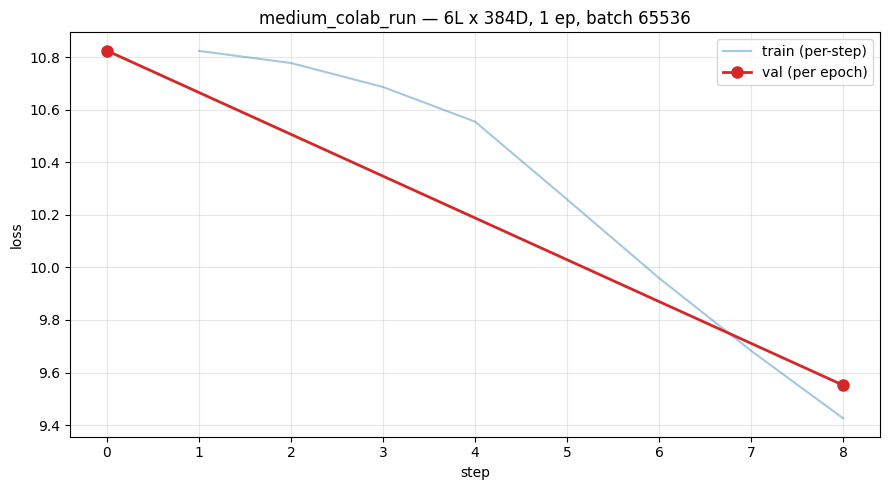

best val loss: 9.5517
final train loss: 9.4255


In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
if losses:
    steps_t, vals_t = zip(*losses)
    ax.plot(steps_t, vals_t, alpha=0.4, label="train (per-step)", color="C0")
    # smoothed
    w = max(1, len(vals_t) // 50)
    if w > 1:
        smooth = np.convolve(vals_t, np.ones(w) / w, mode="valid")
        ax.plot(steps_t[w-1:], smooth, label=f"train (smoothed, w={w})", color="C0", linewidth=2)
if val_history:
    steps_v, losses_v, _ = zip(*val_history)
    ax.plot(steps_v, losses_v, "o-", color="C3", label="val (per epoch)", linewidth=2, markersize=8)
ax.set_xlabel("step")
ax.set_ylabel("loss")
ax.set_title(f"{run_name} — {n_layer}L x {n_embd}D, {num_epochs} ep, batch {total_batch_size}")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"best val loss: {min_val_loss:.4f}")
print(f"final train loss: {losses[-1][1]:.4f}" if losses else "no training steps run")
